# Learning module 15 — Open the observed movie and verify its details

**Small milestone:** identify the unique exact-title candidate in fresh Search results, open it once, capture its details, and check the captured title/year against the scenario. Then leave the automation session closed. We do not continue into cast or related movies.

### Separate selection from verification

Our Search XML merges many cards' ratings/years into one shared accessibility label. That label cannot reliably associate `2014` with a particular card. We therefore select a **unique exact-title candidate**, explicitly record that its year is unverified before opening, and verify the release year on its own details screen. If multiple exact-title candidates exist, this exercise stops instead of choosing the first.

The numeric movie ID is extracted from the newly observed button name; it is not a hardcoded known TMDB ID. App source defines the route/identifier pattern in `catalog_page_state.dart` and `catalog_movie_card.dart`, so the expected details container is `movies.search.movie.{observed_id}.screen`. The live locator is checked for one matching, visible, enabled button before the single click. [Native locator strategies](https://appium.github.io/appium-xcuitest-driver/latest/reference/locator-strategies/)

### Executor first, analyzer afterward

The first cell performs the action and captures evidence. The second cell reads the saved details XML and performs the title/year checks **after the session has closed**. This previews the future Executor → Analyzer boundary using ordinary Python; no agents or graph are introduced yet.

`catalog_view.dart` defines a movie-title semantic header and a release-metadata block beginning with year and runtime. Verification must use that source-backed structure inside the selected movie's details container. Finding `2014` anywhere in the entire screen would be insufficient: an overview or related movie could contain it. [Native attributes and traits](https://appium.github.io/appium-xcuitest-driver/latest/reference/element-attributes/)

**Prerequisites:** select the project `.venv` kernel and run this notebook's setup cells. Leave current-query Search results visible by running module 14 first. This exercise does not repeat the query or navigate to Search automatically. Run serially on the selected Simulator. The earlier dependency findings remain unresolved.

The action retains the independent before/after XML/PNG capture and owned-process cleanup used in modules 13/14. A failed/uncertain click is not retried. Primary loading errors block verification; ancillary cast/artwork results are outside these two assertions. Existing app cache behavior means successful UI checks do not prove a fresh backend request.


The native Search marker is a leaf in our observed hierarchy. It identifies the active screen but does not contain its controls as children. Candidate lookup therefore uses current visible input/heading evidence and branch-specific movie identifiers across the fresh hierarchy. The details view also exposes a leaf marker in our native snapshot, despite its Flutter semantics-container declaration. We bind the native region through the smallest shared ancestor of the unique page marker, Back control, and movie-specific Favorite control. A semantics identifier alone never guarantees an XML parent-child relationship.


**Replaying from an open details page:** use its Back control to restore Search results first. This app retains each tab's navigation stack; tapping the already-selected Search tab does not itself return to the Search root. This is a prerequisite step, not an extra movie-open action inside this exercise.


## This notebook

Part **15 — Open the observed movie and check title/year** of the learning sequence. [Notebook index](README.md).

Select the project's `.venv` Python kernel and run this notebook from top to bottom. Its Python setup is included locally; running another notebook in another kernel does not populate this one's variables or PATH. The supported working directories are the project root, `server/`, and `server/sample_scenarios/`.

**Execution scope:** Requires current-query results; one movie open and offline assertions.

Saved lesson outputs and embedded screenshots are historical snapshots preserved during the split on November 3, 2026. Newly included setup cells have no saved outputs. Rerunning an executable scenario creates fresh local artifacts; these continue living in `server/.tools/`, not beside the notebooks.

**App-state prerequisite:** Python setup does not navigate the app. Leave the scenario query/results visible using [lesson 14](14_search_query.ipynb). From an open details page, use its Back control first; selecting the Search tab retains that branch's navigation stack.

### Setup for this notebook

These source-only prerequisite cells are repeated intentionally so the lesson is runnable in a fresh kernel. They configure local values/environment and inspect tool versions; they do not launch an Appium server, create a session, or tap/type in the app. The original lessons remain linked for explanation.


In [1]:
# Setup: Sample scenario input (lesson 01)
from pprint import pprint

scenario_text = (
    "In Movies, search for Interstellar, open the 2014 movie, "
    "and verify that its details show the title Interstellar "
    "and release year 2014."
)

scenario_input = {
    "instruction": scenario_text,
    "application_name": "Movies",
    "application_profile_ref": None,
    "requested_actions": [
        "search_for_movie",
        "open_matching_movie_details",
    ],
    "search_query": "Interstellar",
    "target_item_identity": {"title": "Interstellar", "release_year": 2014},
    "expected_title": "Interstellar",
    "expected_release_year": 2014,
    "title_matching_rule": "exact",  # Proposed comparison rule for this exercise.
}

pprint(scenario_input, sort_dicts=False)


{'instruction': 'In Movies, search for Interstellar, open the 2014 movie, and '
                'verify that its details show the title Interstellar and '
                'release year 2014.',
 'application_name': 'Movies',
 'application_profile_ref': None,
 'requested_actions': ['search_for_movie', 'open_matching_movie_details'],
 'search_query': 'Interstellar',
 'target_item_identity': {'title': 'Interstellar', 'release_year': 2014},
 'expected_title': 'Interstellar',
 'expected_release_year': 2014,
 'title_matching_rule': 'exact'}


In [2]:
# Setup: Recorded run profile (lesson 03)
from pprint import pprint

run_profile = {
    "id": "movies-ios-local",
    "platform": "ios",
    "execution_provider": "local",
    "app_bundle_id": "com.example.movies",
    "simulator_udid": "4F0707AE-45BC-464D-9099-6EE76C3740A9",
}

app_profiles = {run_profile["id"]: run_profile}
scenario_input["application_profile_ref"] = run_profile["id"]
selected_profile = app_profiles[scenario_input["application_profile_ref"]]

print("Scenario profile reference:", scenario_input["application_profile_ref"])
pprint(selected_profile, sort_dicts=False)


Scenario profile reference: movies-ios-local
{'id': 'movies-ios-local',
 'platform': 'ios',
 'execution_provider': 'local',
 'app_bundle_id': 'com.example.movies',
 'simulator_udid': '4F0707AE-45BC-464D-9099-6EE76C3740A9'}


In [3]:
# Setup: Local Node activation (lesson 05)
import os
from pathlib import Path
import shutil
import subprocess

notebook_cwd = Path.cwd().resolve()
server_candidates = (notebook_cwd, notebook_cwd / "server", *notebook_cwd.parents)
server_dir = next((candidate for candidate in server_candidates
                   if (candidate / ".node-version").is_file()
                   and (candidate / "package.json").is_file()
                   and (candidate / "sample_scenarios").is_dir()), None)
if server_dir is None:
    raise RuntimeError("Run from the project root, server, or sample_scenarios folder.")

node_version = (server_dir / ".node-version").read_text().strip()
node_bin = server_dir / ".tools" / f"node-v{node_version}-darwin-arm64" / "bin"
if not (node_bin / "node").is_file():
    raise FileNotFoundError(f"Project-local Node is missing: {node_bin}")

path_entries = [entry for entry in os.environ.get("PATH", "").split(os.pathsep)
                if entry != str(node_bin)]
os.environ["PATH"] = os.pathsep.join([str(node_bin), *path_entries])

print("Selected Node:", shutil.which("node"))
print("Node version:", subprocess.check_output(["node", "--version"], text=True, timeout=10).strip())
print("npm version:", subprocess.check_output(["npm", "--version"], text=True, timeout=10).strip())


Selected Node: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/node-v24.22.2-darwin-arm64/bin/node
Node version: v24.22.2
npm version: 11.19.1


In [4]:
# Setup: Local Appium activation (lesson 06)
import json
import os
import shutil
import subprocess

if "server_dir" not in globals() or "node_bin" not in globals():
    raise RuntimeError("Run the Node setup cell in this notebook first.")
if shutil.which("node") != str(node_bin / "node"):
    raise RuntimeError("Reactivate the project-local Node runtime first.")

appium_bin_dir = server_dir / "node_modules" / ".bin"
appium_executable = appium_bin_dir / "appium"
if not appium_executable.is_file():
    raise FileNotFoundError("The project-local Appium package is missing.")

os.environ["APPIUM_HOME"] = str(server_dir / ".tools" / "appium")
os.environ["npm_config_cache"] = str(server_dir / ".tools" / "npm-cache")
path_entries = [entry for entry in os.environ.get("PATH", "").split(os.pathsep)
                if entry != str(appium_bin_dir)]
os.environ["PATH"] = os.pathsep.join([str(appium_bin_dir), *path_entries])

expected_version = json.loads((server_dir / "package.json").read_text())["devDependencies"]["appium"]
actual_version = subprocess.check_output(
    [str(appium_executable), "--version"], cwd=server_dir, text=True, timeout=30
).strip()
if actual_version != expected_version:
    raise RuntimeError(f"Expected Appium {expected_version}, found {actual_version}.")

print("Selected Appium:", shutil.which("appium"))
print("Appium version:", actual_version)
print("Appium home:", os.environ["APPIUM_HOME"])


Selected Appium: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/node_modules/.bin/appium
Appium version: 3.9.0
Appium home: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/appium


dbug Appium Creating hash file directory: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/appium/node_modules/.cache/appium


In [5]:
# Setup: Local iOS options (lesson 09)
import json
from appium.options.ios import XCUITestOptions

if "selected_profile" not in globals():
    raise RuntimeError("Run the scenario/profile setup cells in this notebook first.")
if selected_profile.get("platform") != "ios":
    raise ValueError("This example requires an iOS run profile.")
for field in ["app_bundle_id", "simulator_udid"]:
    value = selected_profile.get(field)
    if not isinstance(value, str) or not value.strip():
        raise ValueError(f"The selected profile needs a nonempty {field}.")

ios_options = XCUITestOptions()
ios_options.udid = selected_profile["simulator_udid"]
ios_options.bundle_id = selected_profile["app_bundle_id"]
ios_options.no_reset = True
ios_options.full_reset = False

session_request = ios_options.to_w3c()
print(json.dumps(session_request, indent=2))


{
  "capabilities": {
    "firstMatch": [
      {}
    ],
    "alwaysMatch": {
      "appium:automationName": "XCUITest",
      "platformName": "iOS",
      "appium:udid": "4F0707AE-45BC-464D-9099-6EE76C3740A9",
      "appium:bundleId": "com.example.movies",
      "appium:noReset": true,
      "appium:fullReset": false
    }
  }
}


In [6]:
import json
import re
import sys
import os
import shutil
import socket
import subprocess
import tempfile
import time
import urllib.error
import urllib.request
from appium import webdriver
from appium.options.ios import XCUITestOptions
from appium.webdriver.client_config import AppiumClientConfig
from selenium.webdriver.common.proxy import Proxy
from appium.webdriver.common.appiumby import AppiumBy
from selenium.webdriver.support.ui import WebDriverWait
from pathlib import Path
from datetime import datetime, timezone
import xml.etree.ElementTree as ET

details_result = None

def movie_page_region(root, screen_name, base):
    # A semantics ID can be a leaf. Bind the region using three page-specific anchors.
    anchor_names = (screen_name, base + ".back", base + ".favorite")
    anchors = []
    for name in anchor_names:
        matches = [node for node in root.iter() if node.get("name") == name and node.get("visible") == "true"]
        if len(matches) > 1:
            raise RuntimeError(f"Multiple visible page anchors: {name}")
        if not matches:
            return None
        anchors.append(matches[0])
    parents = {child: parent for parent in root.iter() for child in parent}
    region = anchors[0]
    while not all(anchor in set(region.iter()) for anchor in anchors):
        region = parents.get(region)
        if region is None:
            raise RuntimeError("Page anchors have no shared native region.")
    if region is root:
        raise RuntimeError("Page anchors only share the document root; scope is ambiguous.")
    return region

if not all(name in globals() for name in ("server_dir", "node_bin", "appium_executable", "ios_options")):
    raise RuntimeError("Run this notebook's setup cells first (and its definitions cell where present).")
if shutil.which("node") != str(node_bin / "node"):
    raise RuntimeError("Reactivate the project-local Node runtime.")
if os.environ.get("APPIUM_HOME") != str(server_dir / ".tools" / "appium"):
    raise RuntimeError("Reactivate the project-local Appium home.")
if ios_options.no_reset is not True or ios_options.full_reset is not False:
    raise ValueError("Rerun this notebook's profile/options setup cells to restore this exercise's explicit reset policy.")

# Revalidate the profile/options and installed target immediately before this run.
if "selected_profile" not in globals():
    raise RuntimeError("Run this notebook's profile setup cell first.")
if selected_profile.get("platform") != "ios" or selected_profile.get("execution_provider") != "local":
    raise ValueError("This example requires the local iOS profile.")
if ios_options.udid != selected_profile["simulator_udid"] or ios_options.bundle_id != selected_profile["app_bundle_id"]:
    raise ValueError("The profile/options differ; rerun this notebook's profile/options setup cells.")
devices = json.loads(subprocess.check_output(
    ["xcrun", "simctl", "list", "devices", "--json"], text=True, timeout=20,
))
targets = [d for entries in devices["devices"].values() for d in entries
           if d["udid"] == ios_options.udid]
if len(targets) != 1 or targets[0]["state"] != "Booted" or not targets[0].get("isAvailable"):
    raise RuntimeError("The selected Simulator must be available and booted.")
app_path = subprocess.check_output(
    ["xcrun", "simctl", "get_app_container", ios_options.udid, ios_options.bundle_id, "app"],
    text=True, timeout=20,
).strip()
if not Path(app_path).is_dir():
    raise RuntimeError("The installed Movies container could not be verified.")

host, port, wda_port = "127.0.0.1", 4723, 8100
with socket.socket() as probe:
    probe.bind((host, port))  # Leave an existing Appium server alone.

connection_options = XCUITestOptions().load_capabilities(ios_options.to_capabilities())
connection_options.set_capability("appium:wdaBindingIP", host)
connection_options.set_capability("appium:wdaLocalPort", wda_port)
server_url = f"http://{host}:{port}"
client_config = AppiumClientConfig(
    remote_server_addr=server_url, timeout=300,
    proxy=Proxy({"proxyType": "direct"}),
    init_args_for_pool_manager={"init_args_for_pool_manager": {"retries": 0}},
)
expected_version = json.loads((server_dir / "package.json").read_text())["devDependencies"]["appium"]
log_dir = server_dir / ".tools" / "logs"
log_dir.mkdir(parents=True, exist_ok=True)
with tempfile.NamedTemporaryFile(mode="w", prefix="movie-details-config-", suffix=".json",
                                 dir=log_dir, delete=False) as config_file:
    json.dump({"server": {}}, config_file)
status_opener = urllib.request.build_opener(urllib.request.ProxyHandler({}))
session_driver, session_process, session_result = None, None, None
with tempfile.NamedTemporaryFile(mode="w", prefix="movie-details-check-", suffix=".log",
                                 dir=log_dir, delete=False) as session_log:
    print("Server/session log:", session_log.name, flush=True)
    try:
        session_process = subprocess.Popen(
            [str(node_bin / "node"), str(appium_executable), "--config", config_file.name,
             "--address", host, "--port", str(port), "--log-no-colors", "--log-timestamp"],
            cwd=server_dir, env=os.environ.copy(), stdout=session_log, stderr=subprocess.STDOUT,
        )
        print("Owned Appium PID:", session_process.pid, flush=True)
        deadline = time.monotonic() + 30
        while time.monotonic() < deadline:
            if session_process.poll() is not None:
                raise RuntimeError(f"Appium exited early; inspect {session_log.name}")
            try:
                with status_opener.open(server_url + "/status", timeout=2) as response:
                    server_status = json.load(response)["value"]
                break
            except urllib.error.URLError:
                time.sleep(0.25)
        else:
            raise TimeoutError(f"Appium startup timed out; inspect {session_log.name}")
        if server_status.get("ready") is not True or server_status.get("build", {}).get("version") != expected_version:
            raise RuntimeError("Appium did not return the expected readiness/version.")
        if session_process.poll() is not None:
            raise RuntimeError("The owned server stopped before session creation.")
        print("Requesting XCUITest session; first WDA setup may take time...", flush=True)
        session_driver = webdriver.Remote(
            command_executor=server_url, options=connection_options, client_config=client_config,
        )
        if not session_driver.session_id:
            raise RuntimeError("The client did not receive a session ID.")
        session_result = {"session_id": session_driver.session_id,
                          "returned_capabilities": session_driver.capabilities}
        client_config.timeout = 20  # Bound each action/observation request after startup.
        observation_root = server_dir / ".tools" / "observations"
        observation_root.mkdir(parents=True, exist_ok=True)
        evidence_dir = Path(tempfile.mkdtemp(prefix="movie-details-", dir=observation_root))
        manifest_path = evidence_dir / "manifest.json"
        if "scenario_input" not in globals():
            raise RuntimeError("Run this notebook's scenario setup cell first.")
        query = scenario_input["search_query"].strip()
        target_title = scenario_input["target_item_identity"]["title"]
        expected_title = scenario_input["expected_title"]
        expected_year = scenario_input["expected_release_year"]
        if not query or not isinstance(target_title, str) or not target_title:
            raise ValueError("The scenario needs a nonempty query and target title.")
        if not isinstance(expected_title, str) or not expected_title or type(expected_year) is not int:
            raise ValueError("The scenario needs an expected title and integer release year.")
        details_result = {
            "session_id": session_driver.session_id,
            "returned_target": {key: session_driver.capabilities.get(key)
                                for key in ("platformName", "platformVersion", "udid", "bundleId")},
            "server_log": session_log.name, "query": query,
            "expected": {"title": expected_title, "release_year": expected_year},
            "selection": {"target_title": target_title, "year_verified_before_open": False,
                          "year_limitation": "Search merges multiple cards' years into one native label."},
            "action": {"attempted": False, "acknowledged": False},
            "executor_status": "not_started", "verification": {"status": "not_checked"}, "evidence": {},
        }

        def save_manifest():
            manifest_path.write_text(json.dumps(details_result, indent=2), encoding="utf-8")

        def capture_phase(phase):
            capture = {"capture_status": "incomplete"}
            details_result["evidence"][phase] = capture
            capture_errors = []
            xml_root = None
            try:
                started = datetime.now(timezone.utc).isoformat()
                xml_text = session_driver.page_source
                completed = datetime.now(timezone.utc).isoformat()
                xml_path = evidence_dir / f"{phase}-hierarchy.xml"
                xml_path.write_text(xml_text, encoding="utf-8")
                capture["hierarchy"] = {"path": str(xml_path), "started_at": started, "completed_at": completed}
                xml_root = ET.fromstring(xml_text)
            except Exception as error:
                capture["hierarchy_error"] = {"type": type(error).__name__, "message": str(error)}
                capture_errors.append(error)
            # Attempt the PNG independently, even when source retrieval/parsing fails.
            try:
                started = datetime.now(timezone.utc).isoformat()
                png = session_driver.get_screenshot_as_png()
                completed = datetime.now(timezone.utc).isoformat()
                if not png.startswith(b"\x89PNG\r\n\x1a\n"):
                    raise ValueError("The screenshot response was not PNG.")
                png_path = evidence_dir / f"{phase}-screen.png"
                png_path.write_bytes(png)
                capture["screenshot"] = {"path": str(png_path), "started_at": started, "completed_at": completed}
            except Exception as error:
                capture["screenshot_error"] = {"type": type(error).__name__, "message": str(error)}
                capture_errors.append(error)
            if not capture_errors:
                capture["capture_status"] = "complete"
            save_manifest()
            if capture_errors:
                raise capture_errors[0]
            return xml_root

        def details_content_ready(driver):
            root = ET.fromstring(driver.page_source)
            region = movie_page_region(root, details_result["details_screen"], details_result["details_base"])
            if region is None:
                return False
            visible = [node for node in region.iter() if node.get("visible") == "true"]
            errors = [node for node in visible if node.get("name") == details_result["details_base"] + ".error"]
            if errors:
                message = " ".join(child.get("label", "") for node in errors for child in node.iter())
                raise RuntimeError("The app reported a primary movie-details error: " + message)
            headers = [node for node in visible
                       if "Header" in [trait.strip() for trait in node.get("traits", "").split(",")]
                       and node.get("label")]
            if headers:
                return {"visible_headers": [dict(node.attrib) for node in headers],
                        "body_marker_present": True, "region_attributes": dict(region.attrib)}
            return False

        primary_error = None
        after_error = None
        try:
            before_root = capture_phase("before")
            search_screens = [node for node in before_root.iter() if node.get("name") == "movies.search.screen"
                              and node.get("visible") == "true"]
            if len(search_screens) != 1:
                raise RuntimeError("Leave current-query Search results visible by running module 14 first.")
            # The Search marker is a native leaf; read current visible branch evidence.
            visible = [node for node in before_root.iter() if node.get("visible") == "true"]
            details_result["selection"]["search_marker_is_leaf"] = len(search_screens[0]) == 0
            fields = [node for node in visible if node.get("name") == "movies.search.query.input"]
            heading = f'Results for “{query}”'
            if len(fields) != 1 or fields[0].get("value") != query or not any(
                node.get("label") == heading for node in visible
            ):
                raise RuntimeError("The visible Search input/results do not match the scenario query.")
            if any(node.get("name") == "movies.search.results.error" for node in visible):
                raise RuntimeError("Search reports an error; retained cards will not be used.")
            candidates = [node for node in before_root.iter()
                          if node.get("type") == "XCUIElementTypeButton"
                          and node.get("label") == f"Open {target_title}"
                          and re.fullmatch(r"movies\.search\.results\.movie\.[0-9]+\.open", node.get("name", ""))]
            details_result["selection"]["exact_title_candidate_count"] = len(candidates)
            if len(candidates) != 1:
                raise RuntimeError(f"Need one exact-title candidate; found {len(candidates)}. No movie was chosen.")
            candidate = candidates[0]
            if candidate.get("visible") != "true" or candidate.get("enabled") != "true":
                raise RuntimeError("The exact-title candidate is not currently visible and enabled.")
            locator = candidate.get("name")
            movie_id = re.fullmatch(r"movies\.search\.results\.movie\.([0-9]+)\.open", locator).group(1)
            details_result["selection"].update(locator=locator, observed_movie_id=movie_id,
                                                observed_label=candidate.get("label"))
            details_result["details_base"] = f"movies.search.movie.{movie_id}"
            details_result["details_screen"] = details_result["details_base"] + ".screen"
            matches = session_driver.find_elements(AppiumBy.ACCESSIBILITY_ID, locator)
            details_result["action"]["live_match_count"] = len(matches)
            if len(matches) != 1:
                raise RuntimeError("The observed movie locator is no longer unique.")
            target = matches[0]
            attributes = {key: target.get_attribute(key) for key in ("type", "name", "label")}
            attributes.update(displayed=target.is_displayed(), enabled=target.is_enabled())
            details_result["action"]["observed_target"] = attributes
            if (attributes["type"] != "XCUIElementTypeButton" or attributes["name"] != locator
                    or attributes["label"] != f"Open {target_title}"
                    or not attributes["displayed"] or not attributes["enabled"]):
                raise RuntimeError("The live target differs from the observed suitable movie button.")
            details_result["action"]["attempted"] = True
            details_result["action"]["started_at"] = datetime.now(timezone.utc).isoformat()
            save_manifest()
            target.click()  # One movie-open call only, with no automatic retry.
            details_result["action"]["acknowledged"] = True
            details_result["action"]["completed_at"] = datetime.now(timezone.utc).isoformat()
            save_manifest()
            ready = WebDriverWait(session_driver, 25, poll_frequency=0.5).until(
                details_content_ready, "The selected movie's details content was not observed ready.",
            )
            details_result["content_observation"] = ready
            details_result["executor_status"] = "details_content_observed"
        except Exception as error:
            primary_error = error
            details_result["executor_status"] = "not_completed"
            details_result["execution_error"] = {"type": type(error).__name__, "message": str(error)}
        finally:
            try:
                capture_phase("after")
            except Exception as error:
                after_error = error
            save_manifest()
            print("Movie details manifest:", manifest_path, flush=True)
            print(json.dumps(details_result, indent=2), flush=True)
        if primary_error is not None:
            raise primary_error
        if after_error is not None:
            raise after_error

    finally:
        active_error = sys.exc_info()[1]
        try:
            if session_driver is not None:
                client_config.timeout = 20  # Bound cleanup requests separately from startup.
                session_driver.quit()
                print("Automation session closed.", flush=True)
        except Exception as cleanup_error:
            if details_result is not None:
                details_result["session_cleanup_error"] = {
                    "type": type(cleanup_error).__name__, "message": str(cleanup_error),
                }
                save_manifest()
            if active_error is None:
                raise
            print("Session cleanup also failed:", type(cleanup_error).__name__, flush=True)
        finally:
            if session_process is not None:
                if session_process.poll() is None:
                    session_process.terminate()
                    try:
                        session_process.wait(timeout=20)
                    except subprocess.TimeoutExpired:
                        session_process.kill()
                        session_process.wait(timeout=5)
                print("Owned Appium process stopped:", session_process.poll() is not None, flush=True)


Server/session log: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/logs/movie-details-check-2sug3fg_.log
Owned Appium PID: 10754
Requesting XCUITest session; first WDA setup may take time...
Movie details manifest: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/observations/movie-details-8cr2s3qd/manifest.json
{
  "session_id": "dc6e7a58-0615-4f7a-88b2-ff4be738e490",
  "returned_target": {
    "platformName": "iOS",
    "platformVersion": "27.0",
    "udid": "4F0707AE-45BC-464D-9099-6EE76C3740A9",
    "bundleId": "com.example.movies"
  },
  "server_log": "/Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/logs/movie-details-check-2sug3fg_.log",
  "query": "Interstellar",
  "expected": {
    "title": "Interstellar",
    "release_year": 2

### Analyze the captured details after cleanup

The next cell reads only the saved manifest and after-XML. It scopes observations to the selected movie's details container and produces separate checks for the expected title and release year. A missing/ambiguous association is blocked; an unambiguous observed mismatch is failed. Both differ from an executor/setup error.

Before/after screenshots provide visual context, while structured checks use native attributes. We will retain the raw observations alongside the result instead of hiding uncertainty behind a single success flag.


Our actual XML exposes title headers as native `Other` nodes with the `Header` trait. It merges the release metadata into one `StaticText` label such as `2014\n2h 49m\nEN\nReleased`. The analyzer finds a unique **observed year/runtime block**, then associates the nearest preceding visible semantic header within the region bound by the selected movie's three page anchors. It reads the year from the first metadata line and compares it with the expected year; it does not search for the expected number anywhere on the screen.

This association is specific to this app's observed native layout and source-defined metadata order. Changed layouts or missing/ambiguous evidence are blocked. Stable identifiers on individual title/year fields would simplify a later adapter; this exercise leaves the client unchanged.


Observed movie identifier: 157336
Title/year verification: {
  "status": "passed",
  "checks": [
    {
      "field": "title",
      "expected": "Interstellar",
      "observed": "Interstellar",
      "passed": true
    },
    {
      "field": "release_year",
      "expected": 2014,
      "observed": 2014,
      "passed": true
    }
  ],
  "observations": {
    "title": "Interstellar",
    "release_year": 2014,
    "title_node": {
      "type": "XCUIElementTypeOther",
      "name": "Interstellar",
      "label": "Interstellar",
      "enabled": "true",
      "visible": "true",
      "accessible": "true",
      "x": "24",
      "y": "386",
      "width": "392",
      "height": "35",
      "index": "3",
      "traits": "Header"
    },
    "metadata_node": {
      "type": "XCUIElementTypeStaticText",
      "value": "2014\n2h 49m\nEN\nReleased",
      "name": "2014\n2h 49m\nEN\nReleased",
      "label": "2014\n2h 49m\nEN\nReleased",
      "enabled": "true",
      "visible": "true",
      "

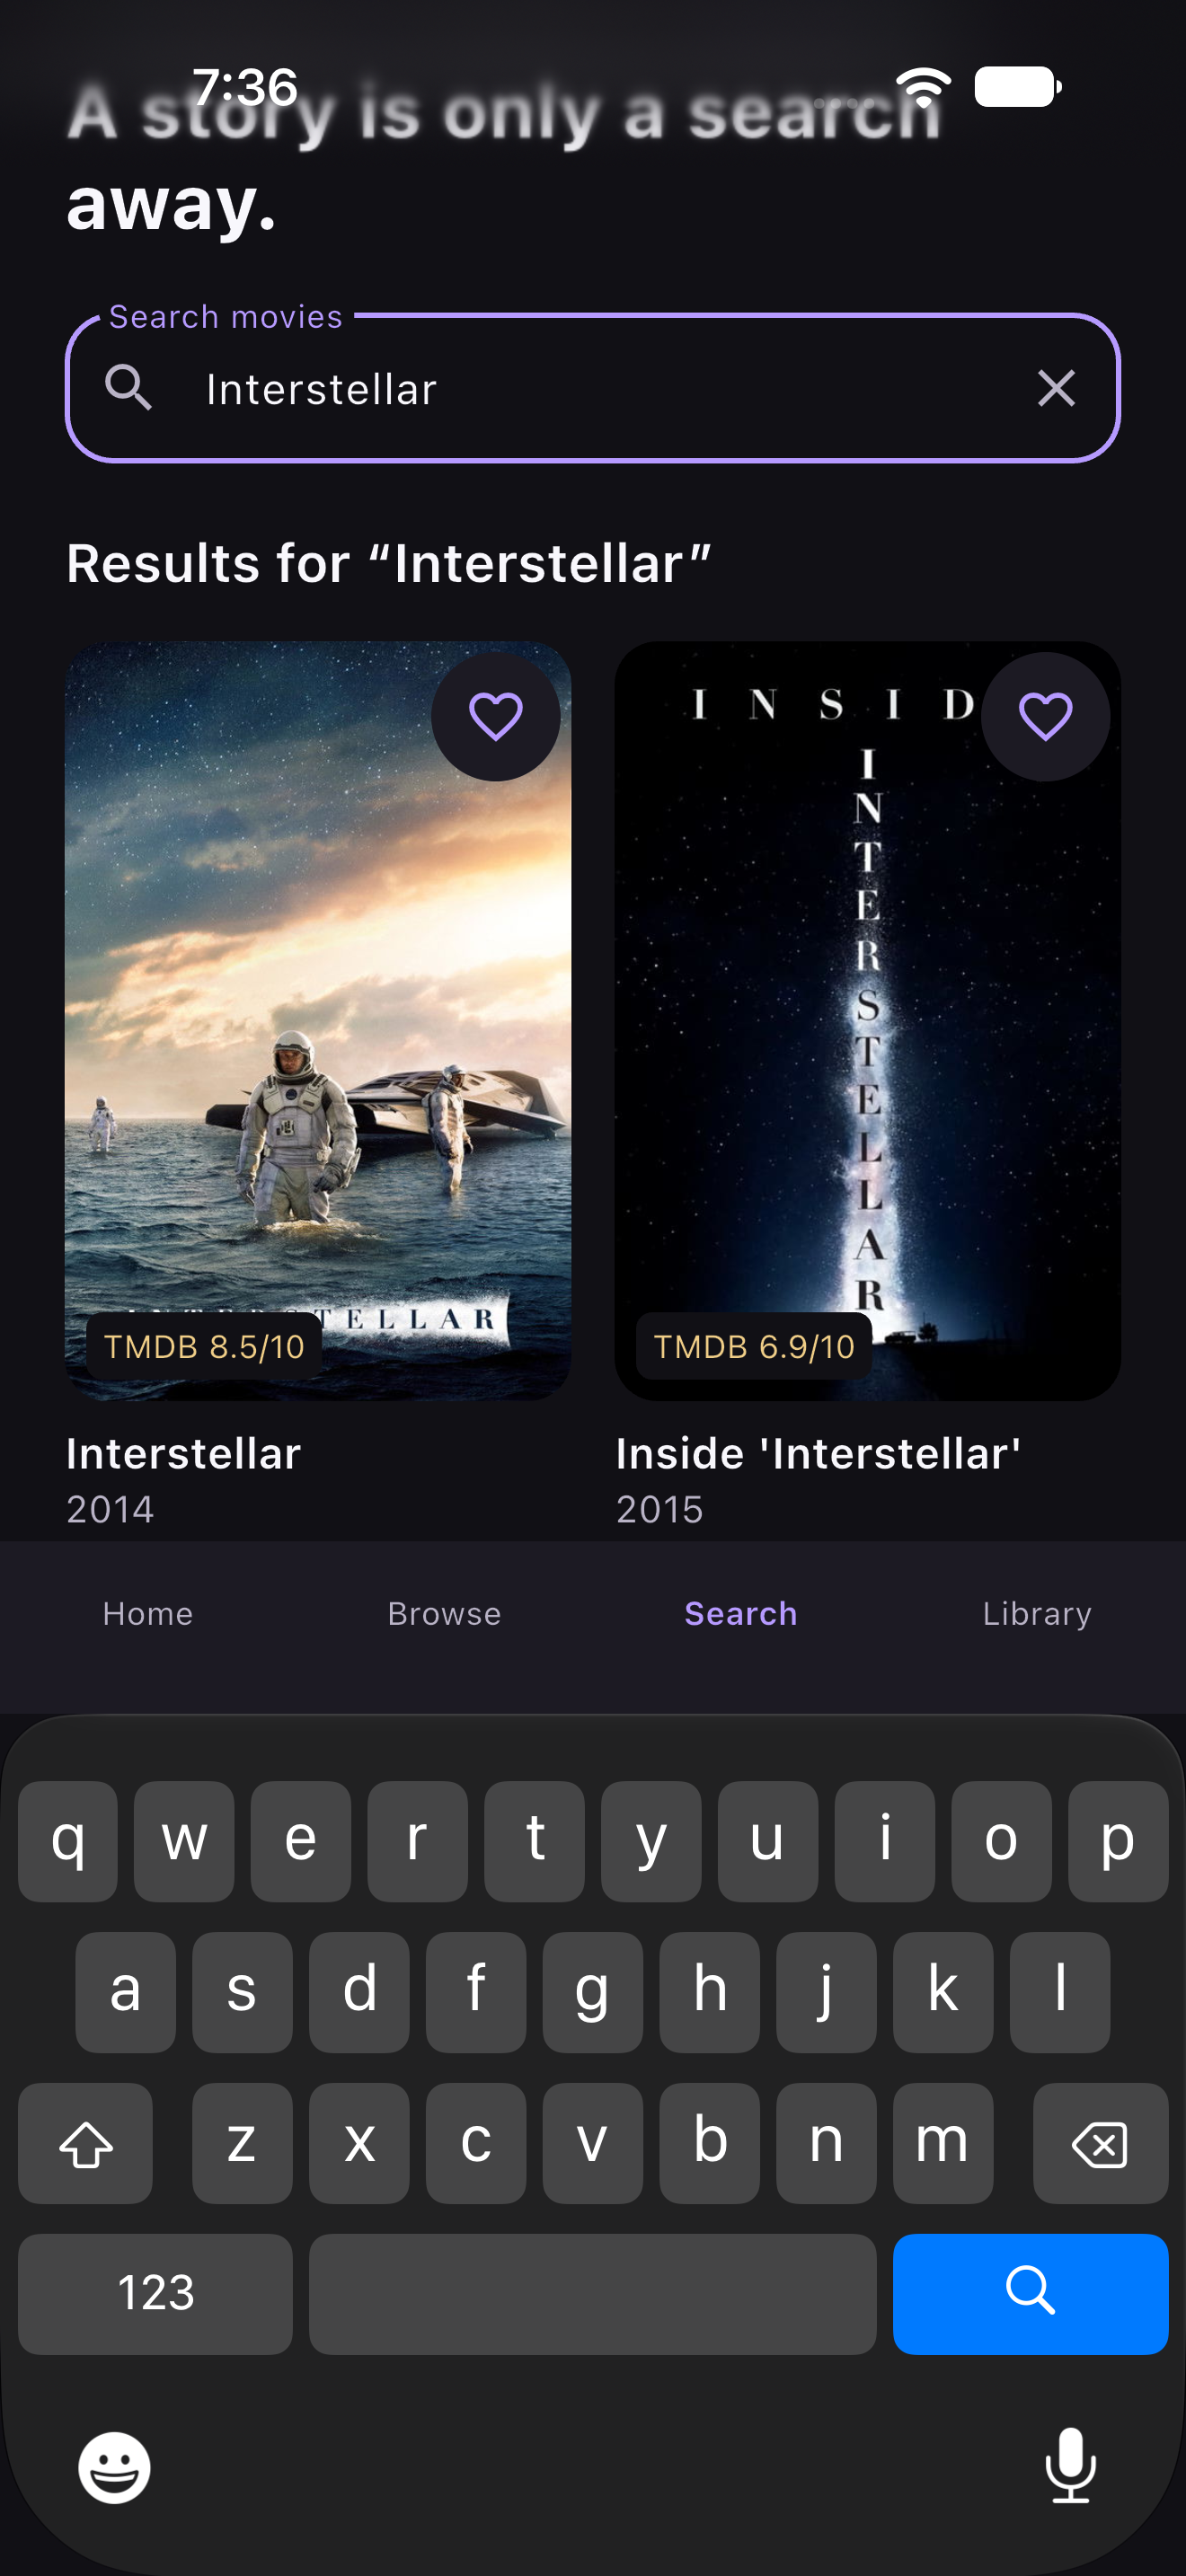

AFTER capture status: complete


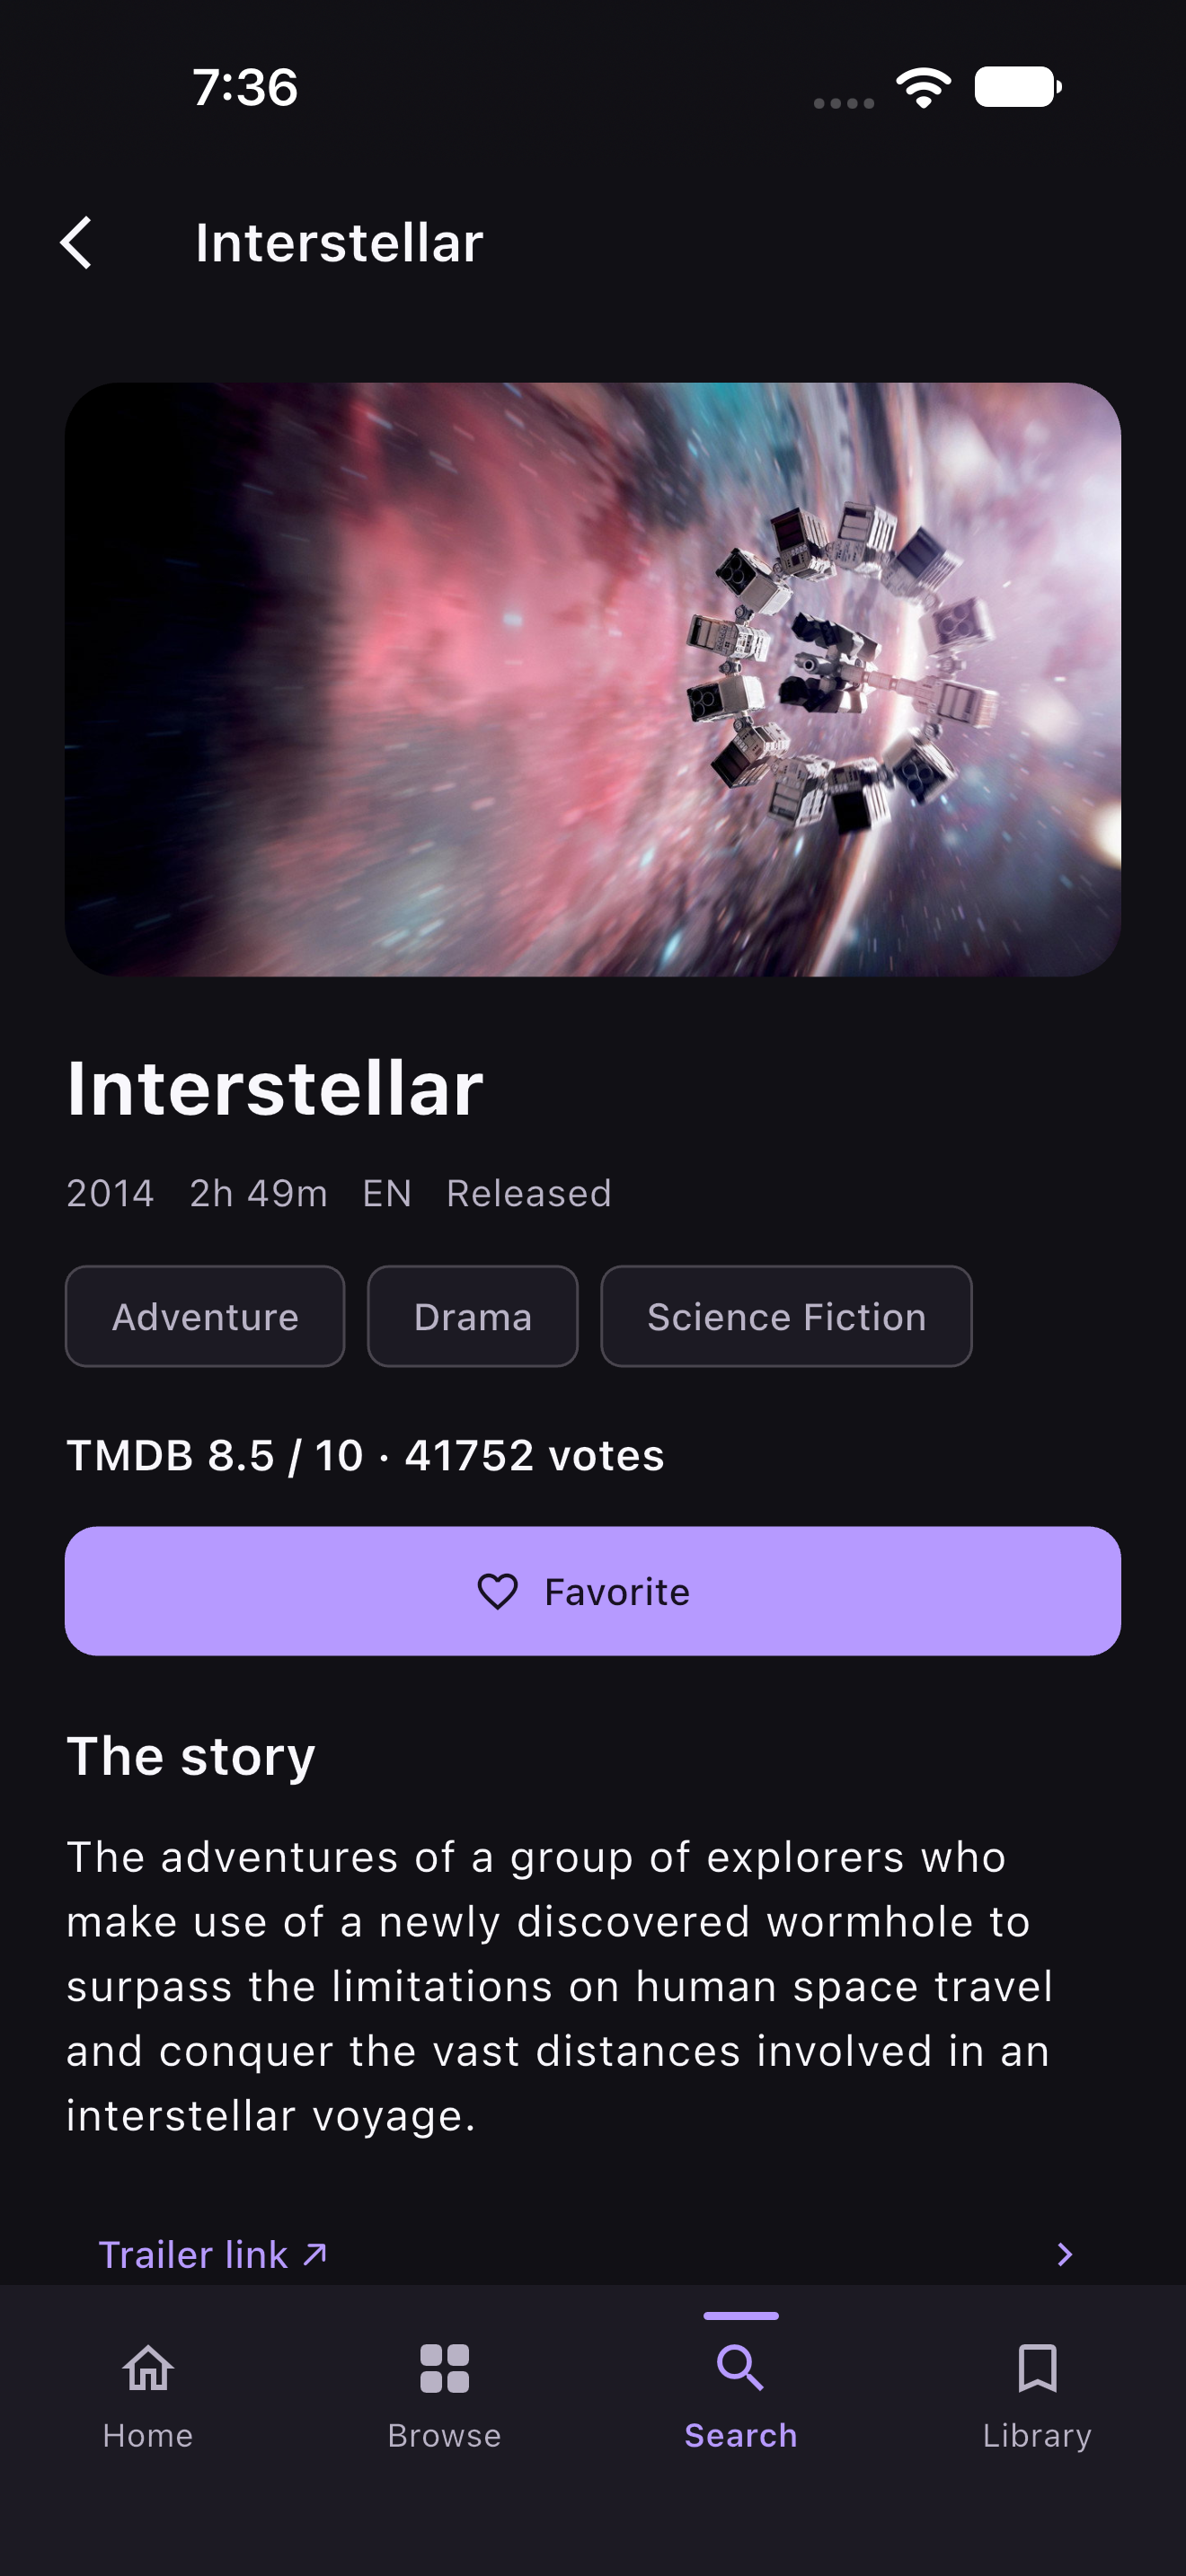

In [7]:
import json
import re
from pathlib import Path
from datetime import datetime, timezone
import xml.etree.ElementTree as ET
from IPython.display import Image, display


def analyze_movie_details(xml_root, screen_name, base, expected):
    report = {"status": "blocked", "checks": [], "observations": {}, "reason": None}
    try:
        region = movie_page_region(xml_root, screen_name, base)
        if region is None:
            raise ValueError("The selected movie's three visible page anchors were not found.")
        visible = [node for node in region.iter() if node.get("visible") == "true"]
        if any(node.get("name") == base + ".error" for node in visible):
            raise ValueError("The selected movie has a visible primary loading error.")
        # Read an observed year, not the expected year's arbitrary occurrence.
        metadata = []
        for node in visible:
            lines = [line.strip() for line in node.get("label", "").splitlines() if line.strip()]
            if (node.get("type") == "XCUIElementTypeStaticText" and len(lines) >= 2
                    and re.fullmatch(r"[0-9]{4}", lines[0])
                    and re.fullmatch(r"[0-9]+h [0-9]+m|Runtime unavailable", lines[1])):
                metadata.append((node, lines))
        if len(metadata) != 1:
            raise ValueError(f"Expected one year/runtime metadata block; found {len(metadata)}.")
        metadata_node, lines = metadata[0]
        metadata_y = float(metadata_node.get("y"))
        # The body title is the nearest semantic header above this metadata block.
        headers = [node for node in visible
                   if "Header" in [trait.strip() for trait in node.get("traits", "").split(",")]
                   and node.get("label") and float(node.get("y", "-1")) >= 0
                   and float(node.get("y")) + float(node.get("height", "0")) <= metadata_y]
        if not headers:
            raise ValueError("No visible semantic title header precedes the metadata block.")
        nearest_y = max(float(node.get("y")) for node in headers)
        nearest_headers = [node for node in headers if float(node.get("y")) == nearest_y]
        if len(nearest_headers) != 1:
            raise ValueError("The header associated with the metadata is ambiguous.")
        title_node = nearest_headers[0]
        observed_title = title_node.get("label")
        observed_year = int(lines[0])
        report["observations"] = {
            "title": observed_title, "release_year": observed_year,
            "title_node": dict(title_node.attrib), "metadata_node": dict(metadata_node.attrib),
            "association": "Nearest visible Header above a unique year/runtime metadata block in the anchored page region.",
        }
        report["checks"] = [
            {"field": "title", "expected": expected["title"], "observed": observed_title,
             "passed": observed_title == expected["title"]},
            {"field": "release_year", "expected": expected["release_year"], "observed": observed_year,
             "passed": observed_year == expected["release_year"]},
        ]
        report["status"] = "passed" if all(check["passed"] for check in report["checks"]) else "failed"
    except (ValueError, TypeError, RuntimeError) as error:
        report["reason"] = str(error)
    return report


if not isinstance(globals().get("details_result"), dict):
    raise RuntimeError("Run the movie-details executor cell before analysis.")
saved_details = json.loads(manifest_path.read_text(encoding="utf-8"))
after_evidence = saved_details["evidence"].get("after", {})
if "hierarchy" not in after_evidence:
    raise RuntimeError("No after-hierarchy was saved; verification remains blocked.")
root = ET.parse(after_evidence["hierarchy"]["path"]).getroot()
report = analyze_movie_details(root, saved_details["details_screen"], saved_details["details_base"],
                               saved_details["expected"])
report["analyzed_at"] = datetime.now(timezone.utc).isoformat()
report["source_path"] = after_evidence["hierarchy"]["path"]
saved_details["verification"] = report
manifest_path.write_text(json.dumps(saved_details, indent=2), encoding="utf-8")
details_result = saved_details
print("Observed movie identifier:", saved_details["selection"]["observed_movie_id"])
print("Title/year verification:", json.dumps(report, indent=2))
for phase in ("before", "after"):
    evidence = saved_details["evidence"].get(phase, {})
    print(phase.upper(), "capture status:", evidence.get("capture_status", "not_captured"))
    if "screenshot" in evidence:
        display(Image(filename=evidence["screenshot"]["path"], width=300))
if report["status"] != "passed":
    raise AssertionError(f"Details assertions {report['status']}: inspect the saved report/evidence.")


### Read the details assertions, then pause

This exercise separates **candidate selection**, **click acknowledgment**, **captured details**, and **assertion results**. An observed movie ID binds the dynamic destination to the selected button; a title/year check must still read the destination's actual content.

The two checks cover the details UI in this captured session. They do not establish a fresh TMDB request, verify every field, or constitute a single uninterrupted replay of the entire English scenario. Earlier learning modules used separate preserved sessions.

The session and owned Appium server are closed; Movies may remain on this details page. No return navigation or deeper cast/related action is issued. All XML/PNG artifacts stay under ignored `.tools/observations/`, with real screenshots shown in the notebook.

**Pause here:** after this assertion milestone, the next small step should be organizing the learned observations/actions/checks into a reusable execution boundary before introducing agent decisions. We will choose that next boundary separately.


**Recorded final live verification:** `2026-11-03T04:27:05.312198+00:00` (UTC). Fresh Search evidence exposed one exact-title candidate and its observed ID `157336`. The final executor issued **one movie-open request**, captured the selected details region, deleted its session, and stopped Appium with exit code `0`.

The analyzer then read the saved XML after cleanup:

| Check | Expected | Observed | Result |
| --- | --- | --- | --- |
| Title | Interstellar | Interstellar | Passed |
| Release year | 2014 | 2014 | Passed |

The actual native title node is an `Other` with the `Header` trait. The metadata is a `StaticText` block beginning `2014`, followed by `2h 49m`, `EN`, and `Released`. Readiness and analysis use the observed native roles and the region shared by this movie's page/Back/Favorite anchors, rather than treating an identifier as a parent container.

Offline regression checks against captured XML confirmed that incorrect expected titles/years fail and missing metadata blocks verification. Native-tree assumptions discovered during development were corrected before this final live replay. These checks are distinct from a real application-failure claim.

Saved manifest: `/Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/observations/movie-details-ncyxyb27/manifest.json`. It contains the independent action/capture facts and the title/year verification report. Before/after PNG and XML files are alongside it, ignored by Git; both real screenshots appear above.


[Index](README.md) · [Previous lesson](14_search_query.ipynb) · [Next lesson](16_reusable_ui_operations.ipynb)